# Лабораторная работа № 1. Регрессия качества вина

**Цель.** Предсказать оценку `quality` по химическим характеристикам и типу вина. Сравнить базовую модель, линейную регрессию с полиномиальными признаками, случайный лес и градиентный бустинг по RMSE и MAE. Проверить локальный порог RMSE < 0,70.

**Данные.** `winequality.csv` объединяет 1 599 красных и 4 898 белых образцов UCI Wine Quality. К 11 химическим признакам добавлен `wine_type` (0 — красное, 1 — белое). [Источник данных и лицензия CC BY 4.0](https://archive.ics.uci.edu/dataset/186/wine+quality). [Задание](https://github.com/lesopylka/ml_course_mai/blob/main/regression/lab01.pdf).

## 1. Настройки эксперимента

Для воспроизводимости разбиений и моделей используется `random_state=42`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, QuantileTransformer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, GridSearchCV
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits

In [2]:
RANDOM_STATE = 42
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})

def show_plot():
    """Показать график внутри ноутбука, не создавая отдельный файл."""
    plt.tight_layout()
    plt.show()
    plt.close()
_thread_limits = threadpool_limits(limits=2)

## 2. Анализ исходных данных

Проверены размеры таблицы, пропуски и повторы, распределения признаков и связи с целевой переменной. Обучаемые преобразования оцениваются внутри обучающей выборки.

In [3]:
data = pd.read_csv('winequality.csv', sep=';')  # строка загрузки общего датасета
print('размер:', data.shape)
print(data['wine_type'].map({0: 'красное', 1: 'белое'}).value_counts())
display(data.head())
data.info()

размер: (6497, 13)
wine_type
белое      4898
красное    1599
Name: count, dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


### 2.1. Качество данных

Проверены пропуски, дубли и диапазоны числовых признаков.

In [4]:
display(data.isna().sum().rename('missing').to_frame())
print('Полных дубликатов:', data.duplicated().sum())
assert data.shape == (6497, 13)
assert set(data['wine_type']) == {0, 1}
assert not data.isna().any().any()
assert np.isfinite(data.to_numpy()).all()
display(data.describe().T)

,missing
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Полных дубликатов: 1177


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.2153,1.2964,3.8000,6.4000,7.0000,7.700,15.900
volatile acidity,6497.0,0.3397,0.1646,0.0800,0.2300,0.2900,0.400,1.580
citric acid,6497.0,0.3186,0.1453,0.0000,0.2500,0.3100,0.390,1.660
residual sugar,6497.0,5.4432,4.7578,0.6000,1.8000,3.0000,8.100,65.800
chlorides,6497.0,0.0560,0.0350,0.0090,0.0380,0.0470,0.065,0.611
free sulfur dioxide,6497.0,30.5253,17.7494,1.0000,17.0000,29.0000,41.000,289.000
total sulfur dioxide,6497.0,115.7446,56.5219,6.0000,77.0000,118.0000,156.000,440.000
density,6497.0,0.9947,0.0030,0.9871,0.9923,0.9949,0.997,1.039
pH,6497.0,3.2185,0.1608,2.7200,3.1100,3.2100,3.320,4.010
sulphates,6497.0,0.5313,0.1488,0.2200,0.4300,0.5100,0.600,2.000


**Вывод.** пропусков нет, поэтому заполнение не требуется. масштабы признаков различаются:
например, плотность близка к единице, а концентрация общего диоксида серы - десятки и сотни.
для интерпретации линейных коэффициентов понадобится стандартизация.
дубликаты не удаляем, но учтём их при разбиении, чтобы копии измерений не попали в обе части.

### 2.2. Распределение целевой переменной

`quality` — медиана не менее трёх экспертных оценок.

,count
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5


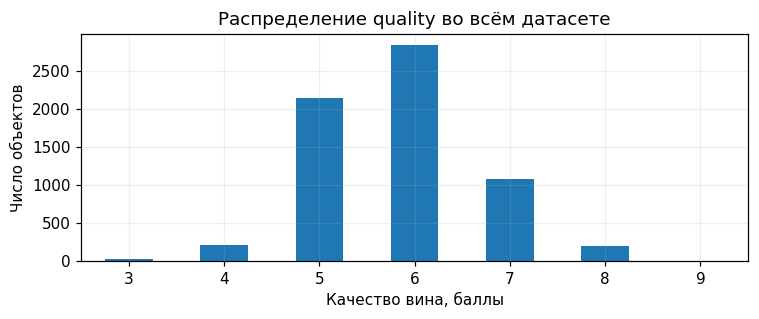

In [5]:
quality_counts = data['quality'].value_counts().sort_index()
display(quality_counts.rename('count').to_frame())
quality_counts.plot.bar(figsize=(7, 3), rot=0)
plt.xlabel('Качество вина, баллы')
plt.ylabel('Число объектов')
plt.title('Распределение quality во всём датасете')
show_plot()

**Вывод.** основная масса оценок - 5 и 6; крайние оценки встречаются редко.
модели будут получать гораздо меньше примеров низкого и высокого качества.
в анализе ошибок отдельно проверим такие группы. редкие оценки не удаляем как «выбросы».

### 2.3. Распределения признаков

Гистограммы построены по всем наблюдениям.

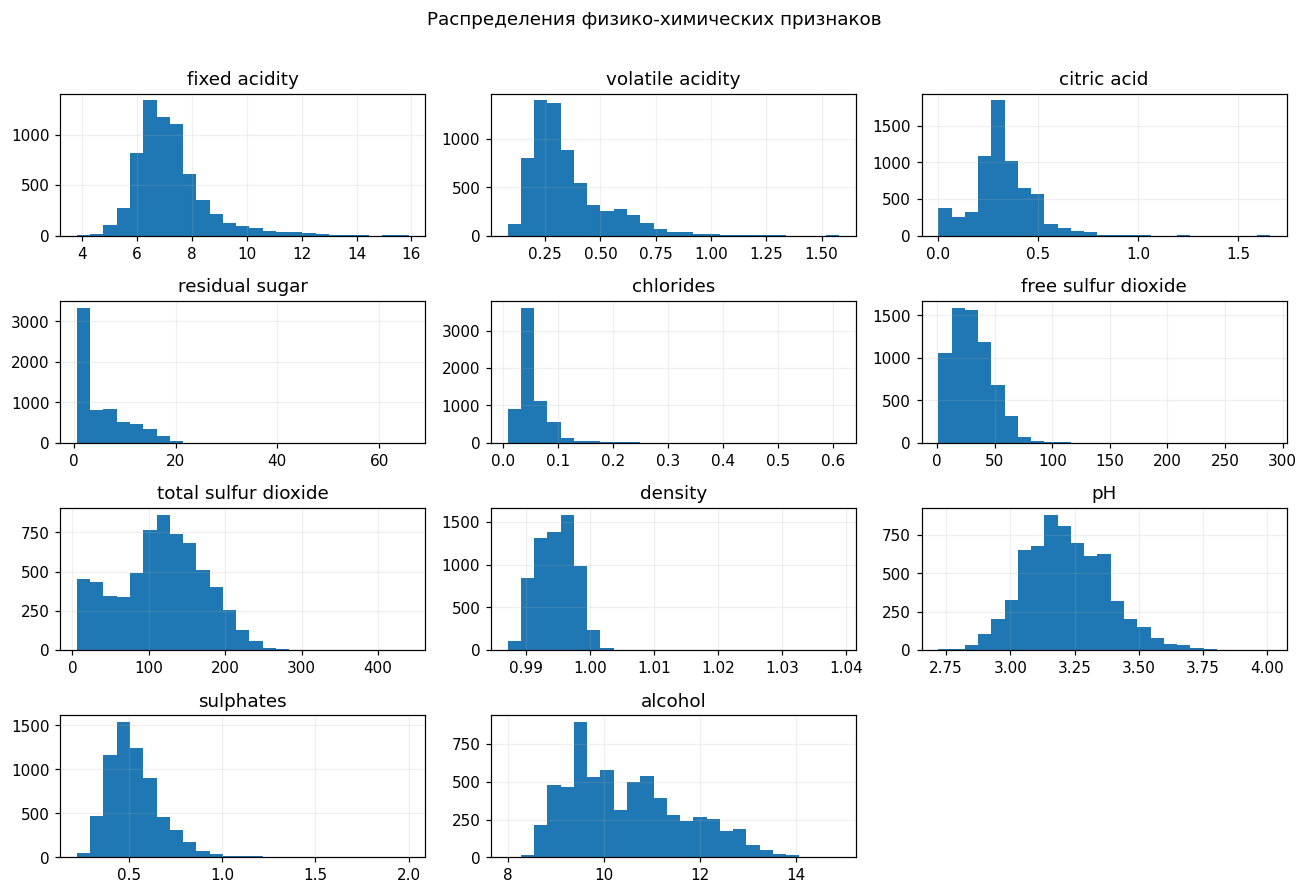

In [6]:
data.drop(columns=['quality', 'wine_type']).hist(figsize=(12, 8), bins=25)
plt.suptitle('Распределения физико-химических признаков', y=1.01)
show_plot()

### 2.4. Корреляции

Рассчитана матрица парных корреляций Пирсона.

,correlation_with_quality
density,-0.3059
volatile acidity,-0.2657
chlorides,-0.2007
fixed acidity,-0.0767
total sulfur dioxide,-0.0414
residual sugar,-0.0370
pH,0.0195
sulphates,0.0385
free sulfur dioxide,0.0555
citric acid,0.0855


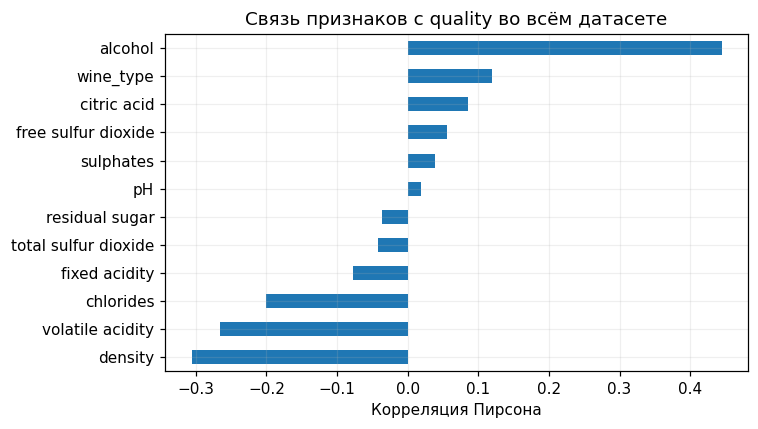

In [7]:
correlations = data.corr()
target_correlations = correlations['quality'].drop('quality').sort_values()
display(target_correlations.rename('correlation_with_quality').to_frame())
target_correlations.plot.barh(figsize=(7, 4))
plt.xlabel('Корреляция Пирсона')
plt.title('Связь признаков с quality во всём датасете')
show_plot()

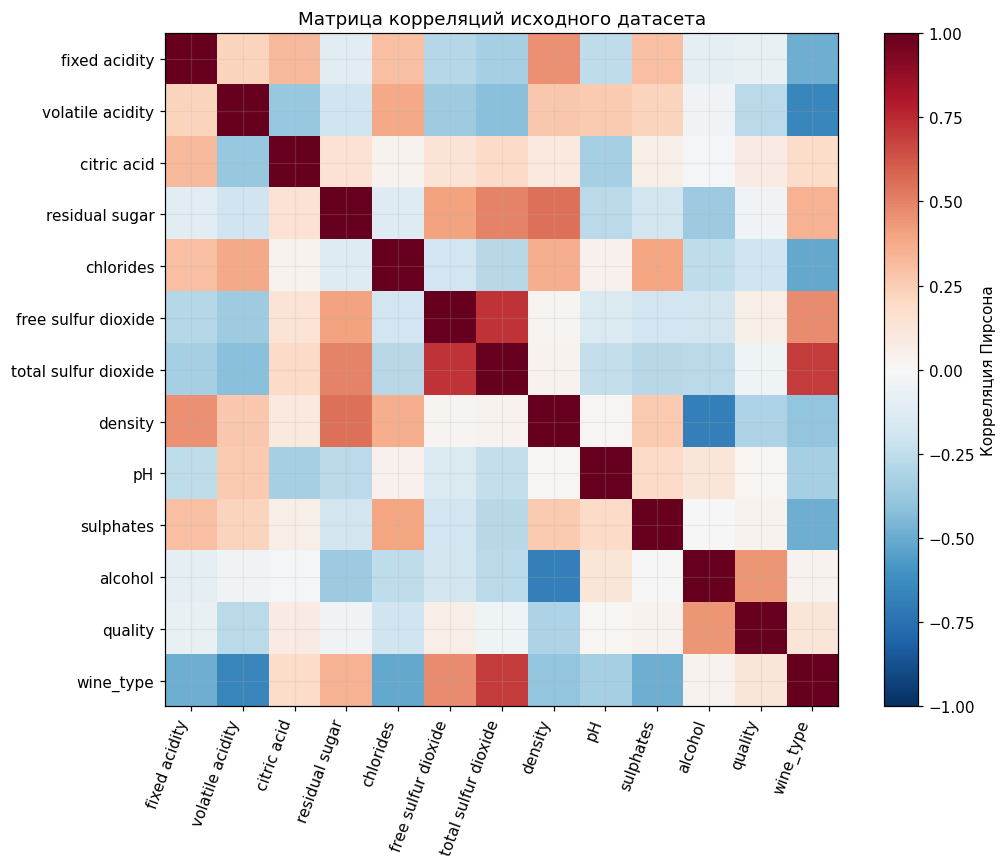

In [8]:
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(correlations, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(correlations)), correlations.columns, rotation=70, ha='right')
ax.set_yticks(range(len(correlations)), correlations.columns)
fig.colorbar(image, ax=ax, label='Корреляция Пирсона')
ax.set_title('Матрица корреляций исходного датасета')
show_plot()

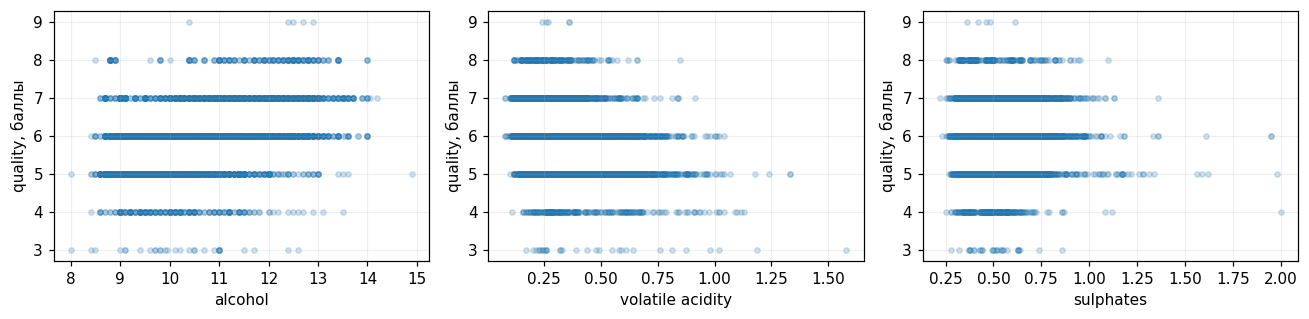

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, feature in zip(axes, ['alcohol', 'volatile acidity', 'sulphates']):
    ax.scatter(data[feature], data['quality'], alpha=0.2, s=12)
    ax.set(xlabel=feature, ylabel='quality, баллы')
show_plot()

Наиболее заметные связи с целевой переменной: положительная для содержания алкоголя и отрицательные для плотности и летучей кислотности. Состав красных и белых вин различается; тип вина включён в признаки.

## 3. Разделение на обучающую и тестовую выборки

`GroupShuffleSplit` откладывает 20% групп. Группы построены по совпадающим значениям всех входных признаков, чтобы одинаковые измерения не оказались в разных выборках.

In [10]:
X = data.drop(columns='quality')
y = data['quality']
groups = pd.util.hash_pandas_object(X, index=False).astype(str)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_groups = groups.iloc[train_idx]

### Проверка разбиения

Сопоставлены число строк и распределение целевой переменной. Проверено отсутствие общих групп.

In [11]:
overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
assert not overlap
print(f'Train: {len(X_train)} строк ({len(X_train) / len(data):.1%})')
print(f'Test: {len(X_test)} строк ({len(X_test) / len(data):.1%})')
print('Общих групп измерений:', len(overlap))
distribution = pd.DataFrame({
    'train_share': y_train.value_counts(normalize=True),
    'test_share': y_test.value_counts(normalize=True),
}).sort_index().fillna(0)
display(distribution)

Train: 5194 строк (79.9%)
Test: 1303 строк (20.1%)
Общих групп измерений: 0


,train_share,test_share
quality,,
3,0.0046,0.0046
4,0.0339,0.0307
5,0.3254,0.3438
6,0.4363,0.4375
7,0.1669,0.1627
8,0.0323,0.0192
9,0.0006,0.0015


## 4. Метрики и кросс-валидация

Основная метрика — RMSE. Дополнительно рассчитывается MAE. Для всех моделей используются одни и те же пять групповых фолдов, без пересечения групп между обучением и валидацией. В рейтинг поиска функции ошибок передаются с отрицательным знаком, поскольку GridSearchCV максимизирует оценку.

In [12]:
cv = GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_train, y_train, train_groups))
for fit_idx, valid_idx in folds:
    assert set(train_groups.iloc[fit_idx]).isdisjoint(train_groups.iloc[valid_idx])

scoring = {'RMSE': 'neg_root_mean_squared_error', 'MAE': 'neg_mean_absolute_error'}
cv_rows = []
print('Созданы 5 одинаковых для всех моделей фолдов; пересечений групп нет.')

Созданы 5 одинаковых для всех моделей фолдов; пересечений групп нет.


In [13]:
def cv_summary(name, scores):
    return {
        'model': name,
        'CV_RMSE': -scores['test_RMSE'].mean(),
        'CV_RMSE_std': scores['test_RMSE'].std(),
        'CV_MAE': -scores['test_MAE'].mean(),
    }

## 5. Базовая модель

`DummyRegressor` предсказывает среднюю оценку качества обучающей части. Среднее минимизирует квадратичную ошибку постоянного прогноза.

In [14]:
baseline = DummyRegressor(strategy='mean')
baseline_scores = cross_validate(baseline, X_train, y_train, cv=folds, scoring=scoring)
baseline.fit(X_train, y_train)
cv_rows.append(cv_summary('Baseline', baseline_scores))
print(f'Константа baseline: {y_train.mean():.4f}')
display(pd.DataFrame([cv_rows[-1]]))

Константа baseline: 5.8263


,model,CV_RMSE,CV_RMSE_std,CV_MAE
0,Baseline,0.8798,0.0115,0.6878


## 6. Линейная регрессия

Конвейер включает `QuantileTransformer`, полиномиальные признаки второй степени, стандартизацию и `LinearRegression`. Преобразования оцениваются на обучающей части каждого фолда.

### 6.1. Обучение конвейера

In [15]:
linear = make_pipeline(
    QuantileTransformer(n_quantiles=200, output_distribution='uniform', random_state=RANDOM_STATE),
    PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), LinearRegression(),
)
linear_name = 'LinearRegression + polynomial features'
with threadpool_limits(limits=2):
    linear_scores = cross_validate(linear, X_train, y_train, cv=folds, scoring=scoring)
    linear.fit(X_train, y_train)
print('модель:', linear_name)

модель: LinearRegression + polynomial features


In [16]:
cv_rows.append(cv_summary(linear_name, linear_scores))
display(pd.DataFrame([cv_rows[-1]]))

,model,CV_RMSE,CV_RMSE_std,CV_MAE
0,LinearRegression + polynomial features,0.7099,0.0165,0.5501


## 7. Случайный лес

Число деревьев фиксировано (400). Подбираются доля признаков и минимальный размер листа по пяти общим фолдам.

In [17]:
forest_search = GridSearchCV(
    RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE, n_jobs=1),
    param_grid={'max_features': [0.8, 1.0], 'min_samples_leaf': [1, 2]},
    scoring=scoring, refit='RMSE', cv=folds, n_jobs=1, error_score='raise',
)
forest_search.fit(X_train, y_train)
forest = forest_search.best_estimator_
print('Лучшие параметры:', forest_search.best_params_)
print(f'Лучший CV RMSE: {-forest_search.best_score_:.4f}')

Лучшие параметры: {'max_features': 0.8, 'min_samples_leaf': 2}
Лучший CV RMSE: 0.6898


In [18]:
best = forest_search.best_index_
cv_rows.append({
    'model': 'Random Forest',
    'CV_RMSE': -forest_search.best_score_,
    'CV_RMSE_std': forest_search.cv_results_['std_test_RMSE'][best],
    'CV_MAE': -forest_search.cv_results_['mean_test_MAE'][best],
})
display(pd.DataFrame(forest_search.cv_results_)[['params', 'mean_test_RMSE', 'rank_test_RMSE']])

,params,mean_test_RMSE,rank_test_RMSE
0,"{'max_features': 0.8, 'min_samples_leaf': 1}",-0.6906,2
1,"{'max_features': 0.8, 'min_samples_leaf': 2}",-0.6898,1
2,"{'max_features': 1.0, 'min_samples_leaf': 1}",-0.6937,3
3,"{'max_features': 1.0, 'min_samples_leaf': 2}",-0.6939,4


## 8. Градиентный бустинг

Подбираются максимальная глубина и число деревьев. Скорость обучения — 0,05; минимальный размер листа — 5.

In [19]:
boosting_search = GridSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE, learning_rate=0.05, min_samples_leaf=5),
    param_grid={'n_estimators': [300, 600], 'max_depth': [4, 5]},
    scoring=scoring, refit='RMSE', cv=folds, n_jobs=1, error_score='raise',
)
boosting_search.fit(X_train, y_train)
boosting = boosting_search.best_estimator_
print('Лучшие параметры:', boosting_search.best_params_)
print(f'Лучший CV RMSE: {-boosting_search.best_score_:.4f}')

Лучшие параметры: {'max_depth': 5, 'n_estimators': 300}
Лучший CV RMSE: 0.7000


In [20]:
best = boosting_search.best_index_
cv_rows.append({
    'model': 'Gradient Boosting',
    'CV_RMSE': -boosting_search.best_score_,
    'CV_RMSE_std': boosting_search.cv_results_['std_test_RMSE'][best],
    'CV_MAE': -boosting_search.cv_results_['mean_test_MAE'][best],
})
display(pd.DataFrame(boosting_search.cv_results_)[['params', 'mean_test_RMSE', 'rank_test_RMSE']])

,params,mean_test_RMSE,rank_test_RMSE
0,"{'max_depth': 4, 'n_estimators': 300}",-0.7036,2
1,"{'max_depth': 4, 'n_estimators': 600}",-0.7089,4
2,"{'max_depth': 5, 'n_estimators': 300}",-0.7000,1
3,"{'max_depth': 5, 'n_estimators': 600}",-0.7044,3


## 9. Выбор модели по кросс-валидации

Для выбора используется средний CV RMSE. GridSearchCV переобучает выбранную конфигурацию каждого ансамбля на всей обучающей выборке.

In [21]:
validation = pd.DataFrame(cv_rows).set_index('model')
winner = validation['CV_RMSE'].idxmin()
models = {'Baseline': baseline, linear_name: linear,
          'Random Forest': forest, 'Gradient Boosting': boosting}
display(validation)
print('Выбранная по CV модель:', winner)

,CV_RMSE,CV_RMSE_std,CV_MAE
model,,,
Baseline,0.8798,0.0115,0.6878
LinearRegression + polynomial features,0.7099,0.0165,0.5501
Random Forest,0.6898,0.0097,0.5325
Gradient Boosting,0.7000,0.0106,0.5440


Выбранная по CV модель: Random Forest


## 10. Оценка на тестовой выборке

Для всех моделей рассчитываются RMSE и MAE на одной отложенной выборке.

In [22]:
predictions = {}
test_rows = []
for name, model in models.items():
    predictions[name] = model.predict(X_test)
    test_rows.append({
        'model': name,
        'RMSE': root_mean_squared_error(y_test, predictions[name]),
        'MAE': mean_absolute_error(y_test, predictions[name]),
        'train_RMSE': root_mean_squared_error(y_train, model.predict(X_train)),
    })
metrics = pd.DataFrame(test_rows).set_index('model').join(validation)
display(metrics)

,RMSE,MAE,train_RMSE,CV_RMSE,CV_RMSE_std,CV_MAE
model,,,,,,
Baseline,0.8470,0.6667,0.8797,0.8798,0.0115,0.6878
LinearRegression + polynomial features,0.6678,0.5243,0.6891,0.7099,0.0165,0.5501
Random Forest,0.6554,0.5066,0.2875,0.6898,0.0097,0.5325
Gradient Boosting,0.6671,0.5222,0.4828,0.7000,0.0106,0.5440


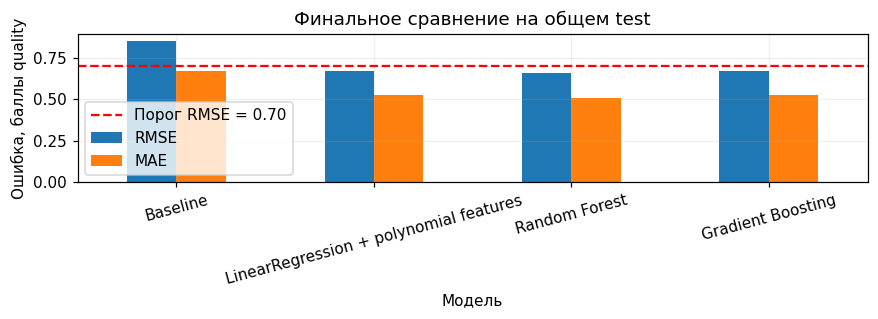

In [23]:
metrics[['RMSE', 'MAE']].plot.bar(figsize=(8, 3), rot=15)
plt.axhline(0.70, color='red', linestyle='--', label='Порог RMSE = 0.70')
plt.ylabel('Ошибка, баллы quality')
plt.xlabel('Модель')
plt.title('Финальное сравнение на общем test')
plt.legend()
show_plot()

In [24]:
test_leader = metrics['RMSE'].idxmin()
gain = 1 - metrics.loc[winner, 'RMSE'] / metrics.loc['Baseline', 'RMSE']
print(f'{winner}: rmse={metrics.loc[winner, "RMSE"]:.4f}, mae={metrics.loc[winner, "MAE"]:.4f}')
print('лидер на test:', test_leader)
threshold_check = metrics.drop(index='Baseline')[['RMSE']].assign(passed=lambda t: t['RMSE'] < 0.70)
display(threshold_check)
print('все три итоговые модели ниже 0.70:', threshold_check['passed'].all())

Random Forest: rmse=0.6554, mae=0.5066
лидер на test: Random Forest


,RMSE,passed
model,,
LinearRegression + polynomial features,0.6678,True
Random Forest,0.6554,True
Gradient Boosting,0.6671,True


все три итоговые модели ниже 0.70: True


На локальной тестовой выборке все три модели, кроме базовой, достигли RMSE < 0,70. Прогнозы оценивались без округления.

## 11. Коэффициенты и важность признаков

### 11.1. Коэффициенты linearregression

q_ означает положение значения в train-распределении. веса относятся к степеням
и произведениям q_, стандартизованным после построения. это не веса исходных измерений.
большой модуль коэффициента не является отдельным причинным эффектом.

,coefficient
q_residual sugar q_density,0.9987
q_density q_wine_type,-0.5234
q_alcohol q_wine_type,-0.4487
q_free sulfur dioxide q_wine_type,0.4417
q_volatile acidity,-0.4139
q_density^2,-0.4074
q_pH,-0.3593
q_residual sugar q_alcohol,0.3560
q_pH q_wine_type,0.3484
q_total sulfur dioxide q_wine_type,0.3402


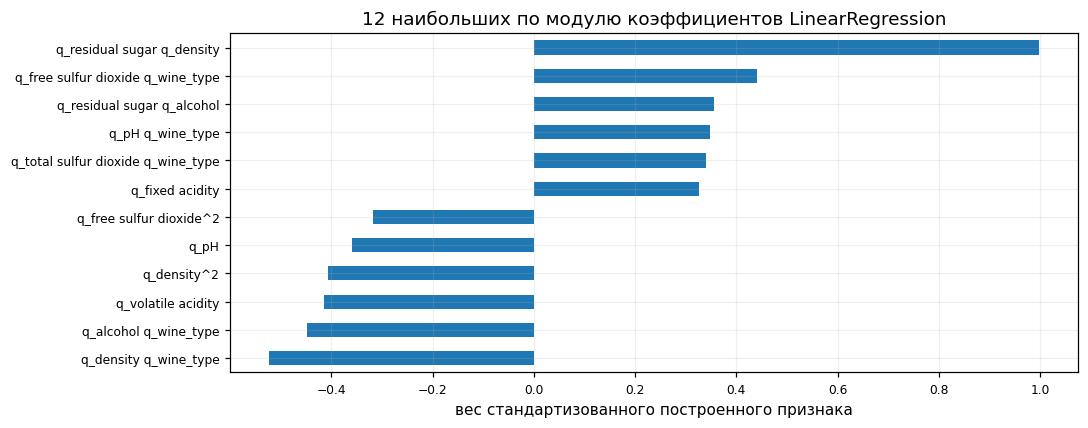

In [25]:
names = linear.named_steps['polynomialfeatures'].get_feature_names_out(['q_' + c for c in X.columns])
coefficients = pd.Series(linear.named_steps['linearregression'].coef_, index=names)
top_coefficients = coefficients.reindex(coefficients.abs().nlargest(12).index)
display(top_coefficients.to_frame('coefficient'))
top_coefficients.sort_values().plot.barh(figsize=(10, 4), fontsize=8)
plt.xlabel('вес стандартизованного построенного признака')
plt.title('12 наибольших по модулю коэффициентов LinearRegression')
show_plot()

**Вывод.** модель учитывает не только значения, но и сочетания признаков.
чтобы сравнить исходные столбцы, дополнительно переставляем каждый из них
на одном валидационном фолде внутри train и измеряем рост rmse.
этот диагностический рейтинг не используется для настройки по test.

In [26]:
importance_fit_idx, importance_valid_idx = folds[0]
with threadpool_limits(limits=2):
    importance_model = clone(linear).fit(X_train.iloc[importance_fit_idx], y_train.iloc[importance_fit_idx])
    permutation = permutation_importance(
        importance_model, X_train.iloc[importance_valid_idx], y_train.iloc[importance_valid_idx],
        scoring='neg_root_mean_squared_error', n_repeats=3, random_state=RANDOM_STATE,
    )
linear_importance = pd.Series(permutation.importances_mean, index=X.columns)
display(linear_importance.sort_values(ascending=False).to_frame('validation_RMSE_increase'))

,validation_RMSE_increase
density,0.3859
wine_type,0.2736
residual sugar,0.1989
volatile acidity,0.1175
total sulfur dioxide,0.0660
alcohol,0.0502
sulphates,0.0455
free sulfur dioxide,0.0418
pH,0.0416
chlorides,0.0237


### 11.2. random forest и gradient boosting

для деревьев используем `feature_importances_` - нормированное уменьшение impurity (mdi)
по разбиениям обученных деревьев. важность не показывает знак зависимости.

,Random Forest,Gradient Boosting
alcohol,0.2336,0.3182
volatile acidity,0.1375,0.1558
free sulfur dioxide,0.0870,0.0855
density,0.0798,0.0525
sulphates,0.0754,0.0744
total sulfur dioxide,0.0740,0.0652
residual sugar,0.0730,0.0713
pH,0.0622,0.0464
chlorides,0.0620,0.0492
citric acid,0.0604,0.0438


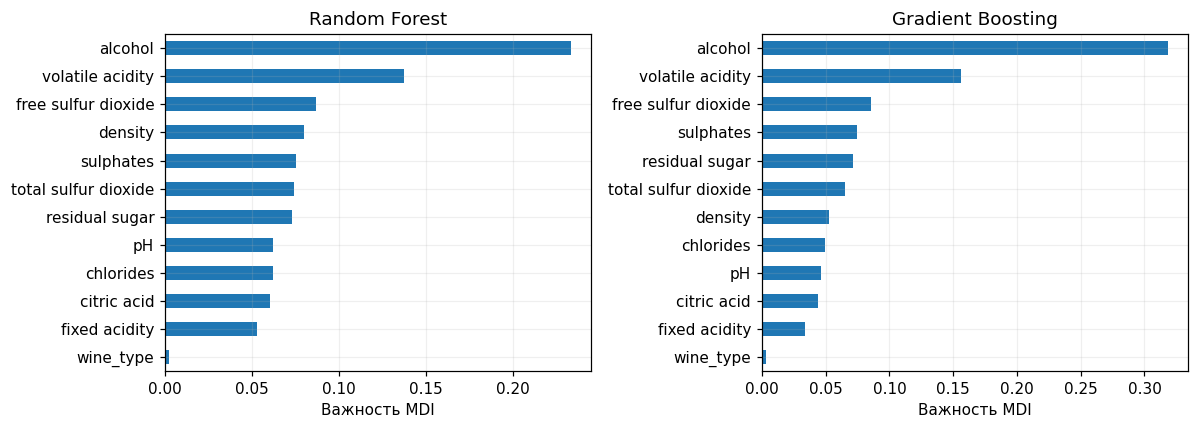

In [27]:
importances = pd.DataFrame({
    'Random Forest': forest.feature_importances_,
    'Gradient Boosting': boosting.feature_importances_,
}, index=X.columns)
display(importances.sort_values('Random Forest', ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, importances.columns):
    importances[name].sort_values().plot.barh(ax=ax)
    ax.set(title=name, xlabel='Важность MDI')
show_plot()

In [28]:
top_features = {
    'EDA (abs correlation)': target_correlations.abs().nlargest(3).index.tolist(),
    'LinearRegression (validation permutation)': linear_importance.nlargest(3).index.tolist(),
    'Random Forest (MDI)': importances['Random Forest'].nlargest(3).index.tolist(),
    'Gradient Boosting (MDI)': importances['Gradient Boosting'].nlargest(3).index.tolist(),
}
display(pd.DataFrame(top_features, index=['1-е место', '2-е место', '3-е место']).T)

,1-е место,2-е место,3-е место
EDA (abs correlation),alcohol,density,volatile acidity
LinearRegression (validation permutation),density,wine_type,residual sugar
Random Forest (MDI),alcohol,volatile acidity,free sulfur dioxide
Gradient Boosting (MDI),alcohol,volatile acidity,free sulfur dioxide


Корреляция описывает парную линейную зависимость, permutation importance — рост ошибки после перестановки признака, MDI — вклад в уменьшение неоднородности в деревьях.

## 12. Анализ ошибок выбранной модели

Остаток рассчитывается как `quality − prediction`; положительное значение соответствует недооценке.

In [29]:
errors = X_test.copy()
errors['quality'] = y_test
errors['prediction'] = predictions[winner]
errors['residual'] = errors['quality'] - errors['prediction']
errors['absolute_error'] = errors['residual'].abs()

### 12.1. Распределение остатков и истинные/предсказанные оценки

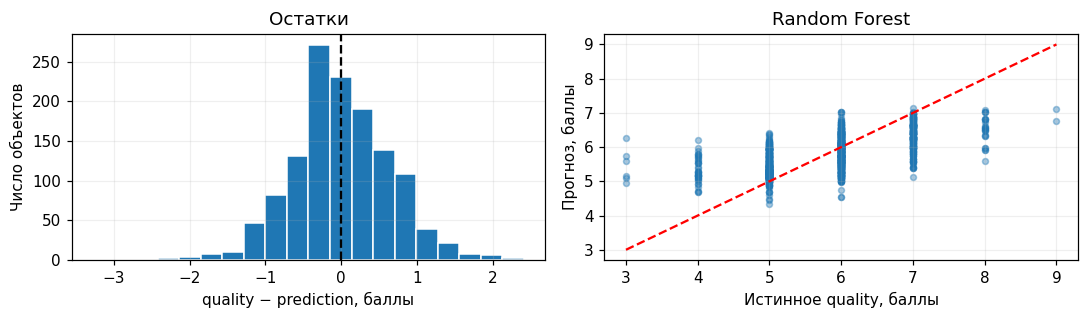

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(errors['residual'], bins=20, edgecolor='white')
axes[0].axvline(0, color='black', linestyle='--')
axes[0].set(xlabel='quality − prediction, баллы', ylabel='Число объектов', title='Остатки')
axes[1].scatter(y_test, errors['prediction'], alpha=0.4, s=15)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--', color='red')
axes[1].set(xlabel='Истинное quality, баллы', ylabel='Прогноз, баллы', title=winner)
show_plot()

**Вывод.** есть ошибки обоих знаков. прогнозы более сосредоточены около средних оценок,
чем истинные значения: низкое качество модель склонна завышать, а высокое - занижать.
проверим это численно по группам quality.

### 12.2. Качество прогноза для разных значений quality

In [31]:
group_rows = []
for quality, group in errors.groupby('quality'):
    group_rows.append({
        'quality': quality, 'n_train': int((y_train == quality).sum()), 'n_test': len(group),
        'mean_prediction': group['prediction'].mean(),
        'MAE': group['absolute_error'].mean(),
        'RMSE': root_mean_squared_error(group['quality'], group['prediction']),
    })
errors_by_quality = pd.DataFrame(group_rows).set_index('quality')
display(errors_by_quality)

,n_train,n_test,mean_prediction,MAE,RMSE
quality,,,,,
3,24,6,5.4706,2.4706,2.5118
4,176,40,5.3260,1.3260,1.3749
5,1690,448,5.4291,0.4485,0.5494
6,2266,570,5.8649,0.3709,0.4560
7,867,212,6.3485,0.6532,0.7671
8,168,25,6.5122,1.4878,1.5388
9,3,2,6.9381,2.0619,2.0705


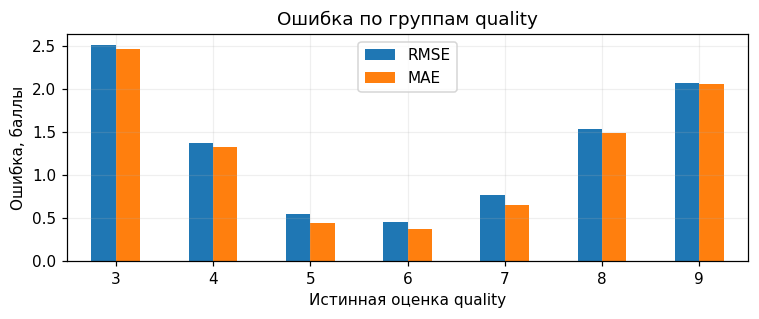

In [32]:
errors_by_quality[['RMSE', 'MAE']].plot.bar(figsize=(7, 3), rot=0)
plt.xlabel('Истинная оценка quality')
plt.ylabel('Ошибка, баллы')
plt.title('Ошибка по группам quality')
show_plot()

**Вывод.** на частых оценках 5 и 6 модель точнее, чем на крайних.
у редких оценок мало обучающих примеров; при квадратичной функции потерь прогноз
стремится к условному среднему. для групп с малым `n_test` сами метрики нестабильны,
поэтому их нельзя трактовать без указания размеров групп.

### 12.3. Объекты с самыми крупными ошибками

In [33]:
worst_errors = errors.sort_values('absolute_error', ascending=False).head(10)
display(worst_errors)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,wine_type,quality,prediction,residual,absolute_error
4906,9.4,0.240,0.29,8.5,0.037,124.0,208.0,0.9940,2.90,0.38,11.0,1,3,6.2744,-3.2744,3.2744
5409,6.8,0.260,0.34,15.1,0.060,42.0,162.0,0.9970,3.24,0.52,10.5,1,3,5.7434,-2.7434,2.7434
4864,4.2,0.215,0.23,5.1,0.041,64.0,157.0,0.9969,3.42,0.44,8.0,1,3,5.5909,-2.5909,2.5909
1854,6.7,0.260,0.39,1.1,0.040,45.0,147.0,0.9935,3.32,0.58,9.6,1,8,5.5888,2.4112,2.4112
2419,6.6,0.360,0.29,1.6,0.021,24.0,85.0,0.9897,3.41,0.61,12.4,1,9,6.7500,2.2500,2.2500
2430,7.4,0.170,0.40,5.5,0.037,34.0,161.0,0.9935,3.05,0.62,11.5,1,4,6.2179,-2.2179,2.2179
1478,7.1,0.875,0.05,5.7,0.082,3.0,14.0,0.9981,3.40,0.52,10.2,0,3,5.1460,-2.1460,2.1460
2472,10.3,0.170,0.47,1.4,0.037,5.0,33.0,0.9939,2.89,0.28,9.6,1,3,5.1060,-2.1060,2.1060
4121,7.3,0.170,0.24,8.1,0.121,32.0,162.0,0.9951,3.17,0.38,10.4,1,8,5.9067,2.0933,2.0933
4124,7.3,0.170,0.24,8.1,0.121,32.0,162.0,0.9951,3.17,0.38,10.4,1,8,5.9067,2.0933,2.0933


для трёх самых больших ошибок найдём пять ближайших объектов **из train** в пространстве
стандартизованных признаков. это помогает проверить, бывают ли у похожих измерений другие
экспертные оценки. соседи используются только для объяснения, не для донастройки модели.

In [34]:
neighbor_scaler = StandardScaler().fit(X_train)
train_scaled = neighbor_scaler.transform(X_train)
example_rows = []
for row_id, row in worst_errors.head(3).iterrows():
    sample_scaled = neighbor_scaler.transform(X_test.loc[[row_id]])
    distances = np.linalg.norm(train_scaled - sample_scaled, axis=1)
    nearest = np.argsort(distances)[:5]
    example_rows.append({
        'row_id': row_id, 'quality': row['quality'], 'prediction': row['prediction'],
        'absolute_error': row['absolute_error'], 'nearby_train_quality': y_train.iloc[nearest].tolist(),
    })
display(pd.DataFrame(example_rows))

,row_id,quality,prediction,absolute_error,nearby_train_quality
0,4906,3.0,6.2744,3.2744,"[6, 8, 8, 6, 4]"
1,5409,3.0,5.7434,2.7434,"[6, 5, 6, 5, 6]"
2,4864,3.0,5.5909,2.5909,"[5, 5, 5, 5, 6]"


In [35]:
for example in example_rows:
    print(f'Строка {example["row_id"]}: quality={example["quality"]:.0f}, '
          f'прогноз={example["prediction"]:.2f}, ошибка={example["absolute_error"]:.2f}; '
          f'оценки соседей train: {example["nearby_train_quality"]}.')

Строка 4906: quality=3, прогноз=6.27, ошибка=3.27; оценки соседей train: [6, 8, 8, 6, 4].
Строка 5409: quality=3, прогноз=5.74, ошибка=2.74; оценки соседей train: [6, 5, 6, 5, 6].
Строка 4864: quality=3, прогноз=5.59, ошибка=2.59; оценки соседей train: [5, 5, 5, 5, 6].


**вывод по примерам.** в таблице видно, что близкие химические измерения могут соответствовать
другим экспертным оценкам. это возможное объяснение крупных промахов: модель обучается на
похожих примерах с иными ответами. крайние оценки также слабо представлены, а свойства вроде
сорта винограда и условий производства не включены в данные. экспертная оценка может быть шумной.
это гипотезы о причинах ошибок, а не доказанные причины для конкретной бутылки.

## 13. Итоги

По кросс-валидации выбран случайный лес. Локальный тестовый RMSE — **0,6554**, MAE — **0,5066**. Ниже приведены итоговые метрики всех моделей.

In [36]:
display(metrics[['RMSE', 'MAE', 'CV_RMSE']])
print('Выбрано по CV:', winner)
print(f'Итоговый test RMSE: {metrics.loc[winner, "RMSE"]:.4f}')
print(f'Итоговый test MAE: {metrics.loc[winner, "MAE"]:.4f}')

,RMSE,MAE,CV_RMSE
model,,,
Baseline,0.8470,0.6667,0.8798
LinearRegression + polynomial features,0.6678,0.5243,0.7099
Random Forest,0.6554,0.5066,0.6898
Gradient Boosting,0.6671,0.5222,0.7000


Выбрано по CV: Random Forest
Итоговый test RMSE: 0.6554
Итоговый test MAE: 0.5066


**Ограничения.** Данные относятся к красному и белому vinho verde. Крайние оценки редки. Локальная тестовая выборка просматривалась при доработке, поэтому качество на ней может быть оптимистичным. На независимой выборке преподавателя оценка не проводилась.